In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [4]:
df=pd.read_csv('C:\\Users\\simra\\OneDrive\\Desktop\\Retail_Sales_Analysis\\data\\retail_sales_dataset.csv')
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [6]:
df['year'] = pd.to_datetime(df['Date']).dt.year

In [10]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,year,Month
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5


In [9]:
df['Month']=pd.to_datetime(df['Date']).dt.month

In [11]:
df['Day']=pd.to_datetime(df['Date']).dt.day

In [14]:
print(df['year'].dtype)

int32


In [31]:
yearly_sales=df.groupby(['year','Month'])['Total Amount'].sum()
yearly_sales 


year  Month
2023  1        35450
      2        44060
      3        28990
      4        33870
      5        53150
      6        36715
      7        35465
      8        36960
      9        23620
      10       46580
      11       34920
      12       44690
2024  1         1530
Name: Total Amount, dtype: int64

In [36]:
df.value_counts('year')

year
2023    998
2024      2
Name: count, dtype: int64

Figure 1: Monthly Revenue Analysis

In [40]:
print(df[df['year']==2024][['Date','Total Amount']].sum())

Date            2024-01-012024-01-01
Total Amount                    1530
dtype: object


In [57]:
sales=df.groupby(df[df['year']==2023]['Month'])['Total Amount'].sum()

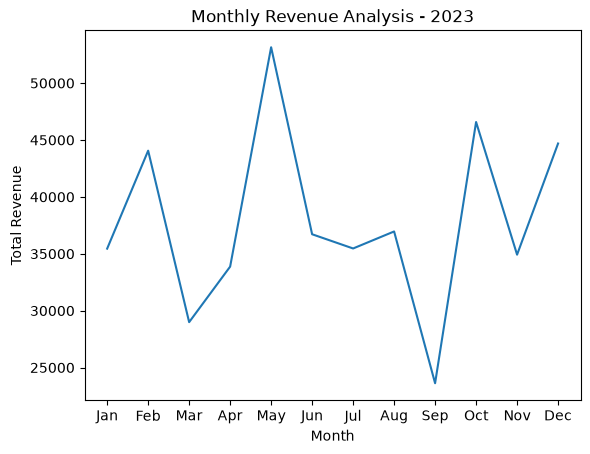

In [60]:
plt.plot(sales.index, sales.values)
plt.xticks(range(1,13),
           labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])
plt.xlabel('Month')
plt.ylabel('Total Revenue')
plt.title('Monthly Revenue Analysis - 2023')
plt.show()

Figure 2: Product Category-wise Revenue Analysis

<Axes: xlabel='Product Category'>

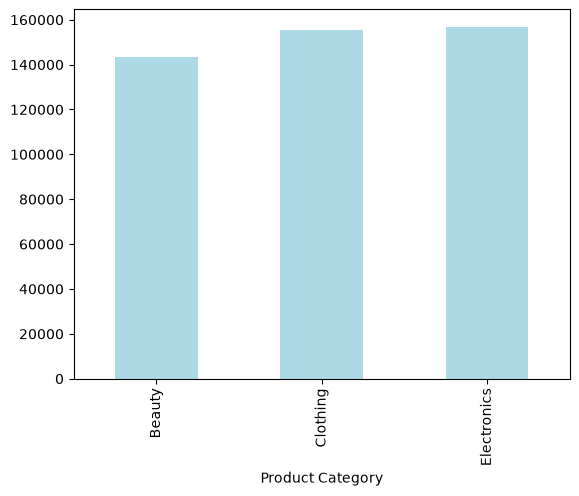

In [68]:
products=df.groupby('Product Category')['Total Amount'].sum()
products.plot(kind='bar', color='lightblue')

Figure 3: Gender-wise Revenue Analysis

<Axes: xlabel='Gender'>

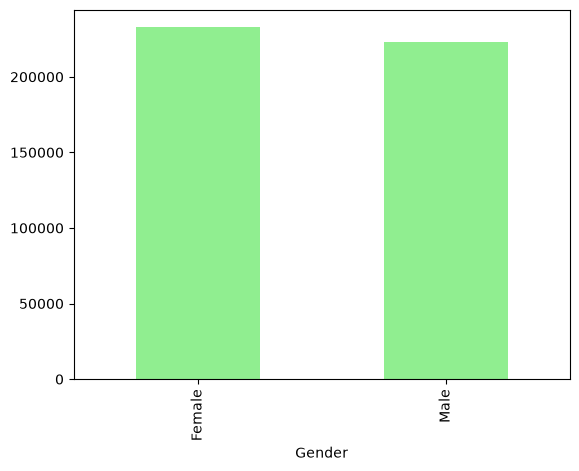

In [74]:
gender_sales=df.groupby('Gender')['Total Amount'].sum()
gender_sales.plot(kind='bar', color='lightgreen')

Figure 4: Gender-wise Quantity Sold

<Axes: xlabel='Gender'>

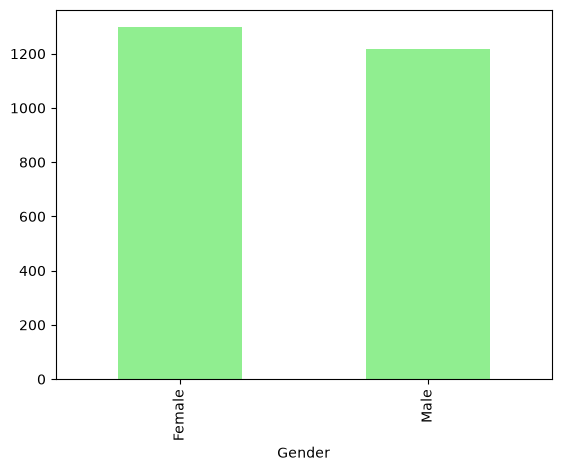

In [75]:
gender_Quantity=df.groupby('Gender')['Quantity'].sum()
gender_Quantity.plot(kind='bar', color='lightgreen')

Figure 5: Age Group-wise Revenue Analysis

np.int64(100690)

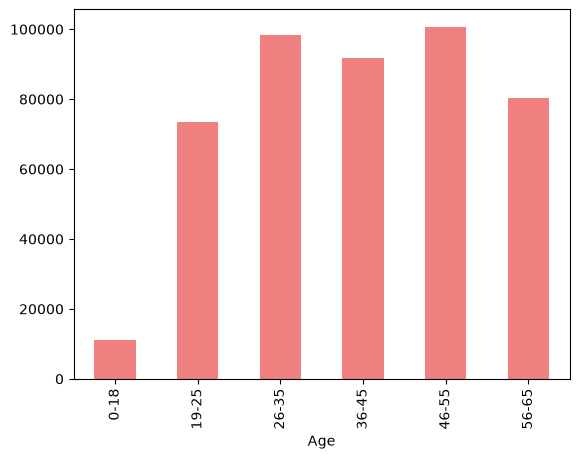

In [85]:
bins=[0,18,25,35,45,55,65,100]
labels=['0-18','19-25','26-35','36-45','46-55','56-65','65+']
age_groups=pd.cut(df['Age'],bins=bins,labels=labels)
age_group_sales=df.groupby(age_groups)['Total Amount'].sum()
age_group_sales.plot(kind='bar', color='lightcoral')



Figure 6: Top 5 Customers by Revenue

<Axes: xlabel='Customer ID'>

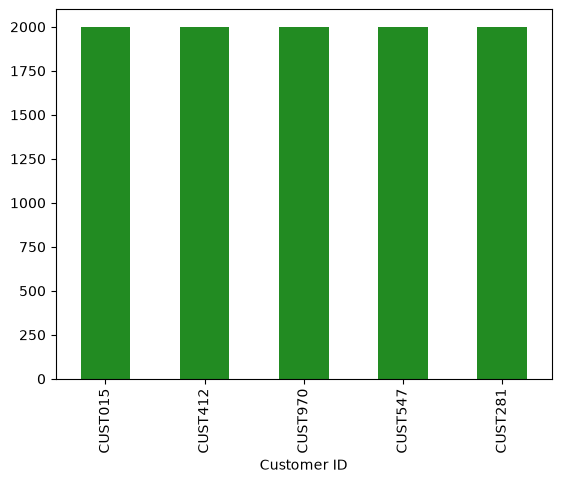

In [89]:
cus_revenue=df.groupby('Customer ID')['Total Amount'].sum().sort_values(ascending=False).head(5)
cus_revenue.plot(kind='bar', color='forestgreen')

Figure 7: Product Category-wise Quantity Sold

<Axes: xlabel='Product Category'>

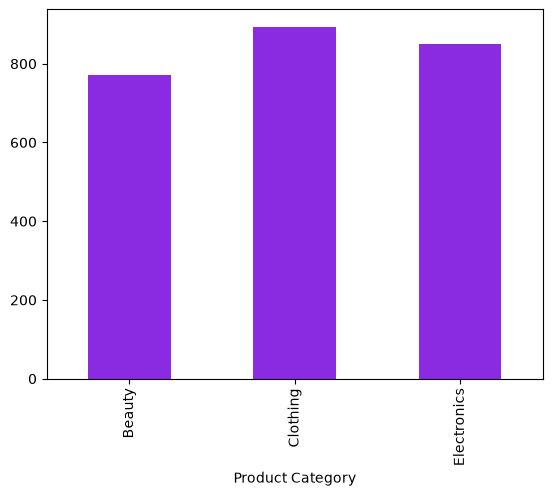

In [92]:
prod_quantity=df.groupby('Product Category')['Quantity'].sum()
prod_quantity.plot(kind='bar', color='blueviolet')

Figure 8: Monthly Quantity Sold Analysis

<Axes: xlabel='Month'>

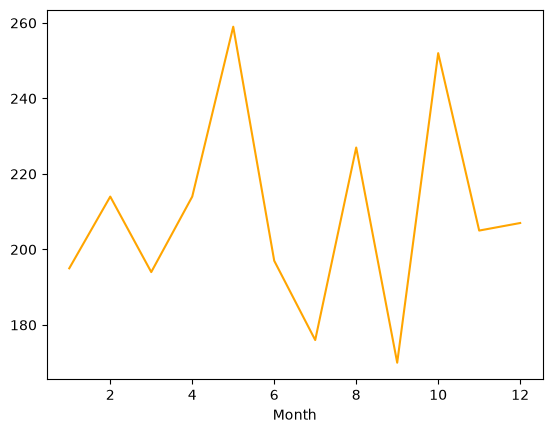

In [93]:
monthly_quantity=df.groupby(df[df['year']==2023]['Month'])['Quantity'].sum()
monthly_quantity.plot(kind='line', color='orange')   

Figure 9: Gender-wise Revenue Contribution

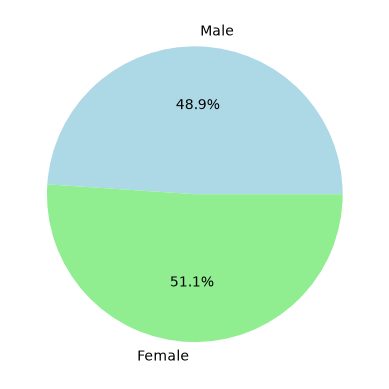

In [97]:
total_revenue=df['Total Amount'].sum()
male=df[df['Gender']=='Male']['Total Amount'].sum()
female=df[df['Gender']=='Female']['Total Amount'].sum()
revenue_male_per=(male/total_revenue)*100
revenue_female_per=(female/total_revenue)*100
plt.pie([revenue_male_per,revenue_female_per],labels=['Male','Female'],autopct='%1.1f%%',colors=['lightblue','lightgreen'])

Figure 10: Top Revenue-Generating Product Categories

<Axes: >

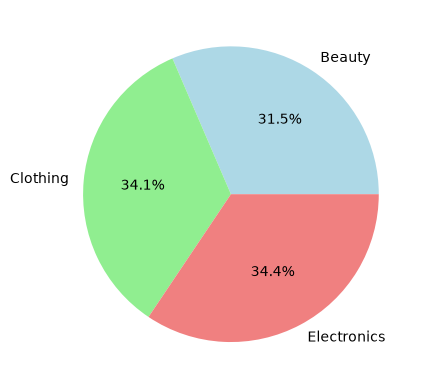

In [98]:
product_revenue=df.groupby('Product Category')['Total Amount'].sum()
product_revenue.plot(kind='pie',autopct='%1.1f%%',colors=['lightblue','lightgreen','lightcoral','orange','blueviolet'])

Figure 11: Quantity vs Revenue Analysis

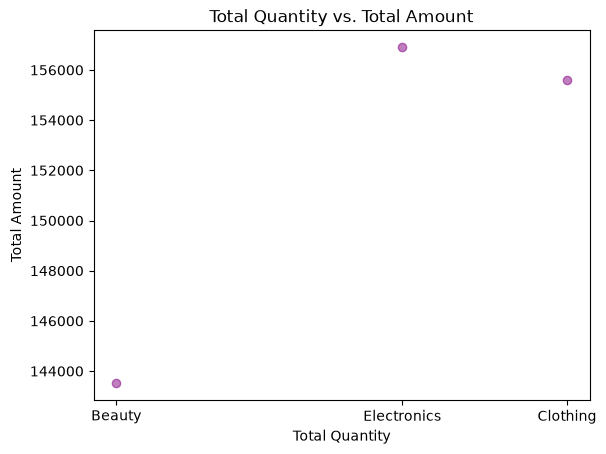

In [147]:
prod_quantity=df.groupby('Product Category')['Quantity'].sum()
prod_Amount=df.groupby('Product Category')['Total Amount'].sum()
plt.scatter(prod_quantity, prod_Amount, color='purple', alpha=0.5)
plt.xticks(prod_quantity, prod_quantity.index, rotation=0)
plt.xlabel('Total Quantity')
plt.ylabel('Total Amount')
plt.title('Total Quantity vs. Total Amount')
plt.show()

Figure 12: Revenue Distribution by Product Category

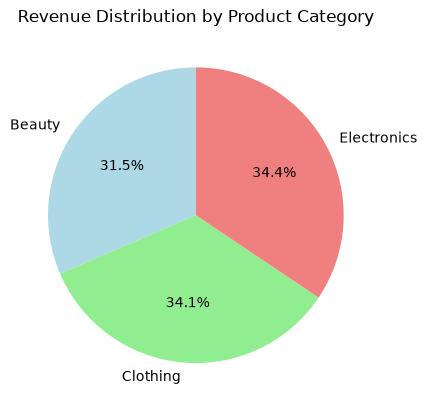

In [ ]:
prod_Amount=df.groupby('Product Category')['Total Amount'].sum()
prod_Amount.plot(kind='pie',autopct='%1.1f%%',colors=['lightblue','lightgreen','lightcoral'],startangle=90)
plt.ylabel('')
plt.title('Revenue Distribution by Product Category')
plt.show()


Figure 13: Monthly Revenue Heatmap

<Axes: ylabel='Product Category'>

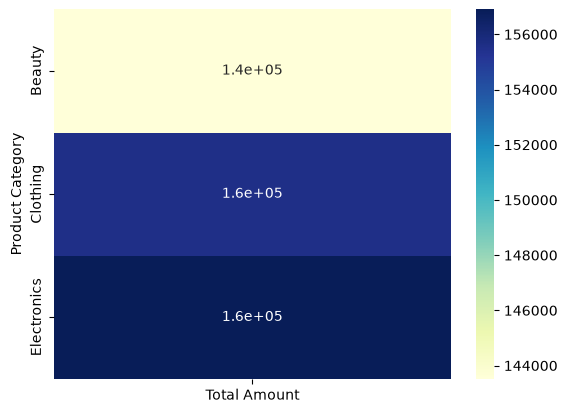

In [125]:


prod_Amount=df.groupby('Product Category')['Total Amount'].sum()
sns.heatmap(prod_Amount.to_frame(), annot=True, cmap='YlGnBu')


Figure 14: Category-wise Revenue Bar Plot

C:\Users\simra\AppData\Local\Temp\ipykernel_13336\850969264.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=prod_Amount.index, y=prod_Amount.values, palette='pastel')


<Axes: xlabel='Product Category'>

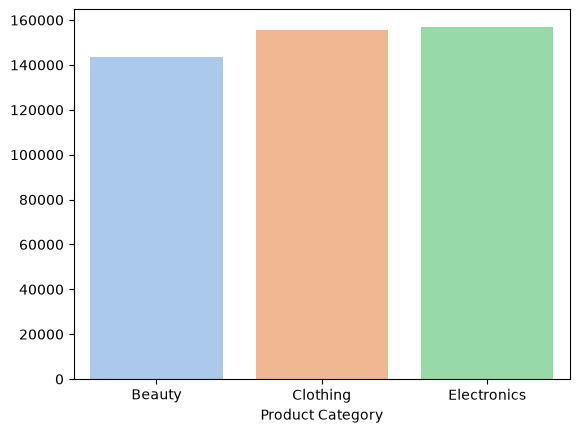

In [ ]:
prod_Amount=df.groupby('Product Category')['Total Amount'].sum()
sns.barplot(x=prod_Amount.index, y=prod_Amount.values, palette='pastel')

plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.title('Category-wise Revenue Analysis')
plt.show()

Figure 15: Monthly Sales Trend

Text(0.5, 1.0, 'Monthly Sales Trend')

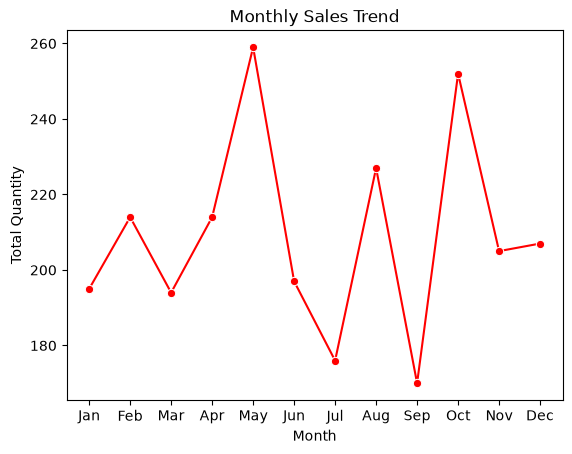

In [132]:
monthly_quantity=df.groupby(df[df['year']==2023]['Month'])['Quantity'].sum()
sns.lineplot(x=monthly_quantity.index, y=monthly_quantity.values, color='red',marker='o') 
plt.xticks(range(1,13),
           labels=['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])  
plt.xlabel('Month')
plt.ylabel('Total Quantity')
plt.title('Monthly Sales Trend')

Figure 16: Gender-wise Quantity Bar Plot

<Axes: ylabel='Gender'>

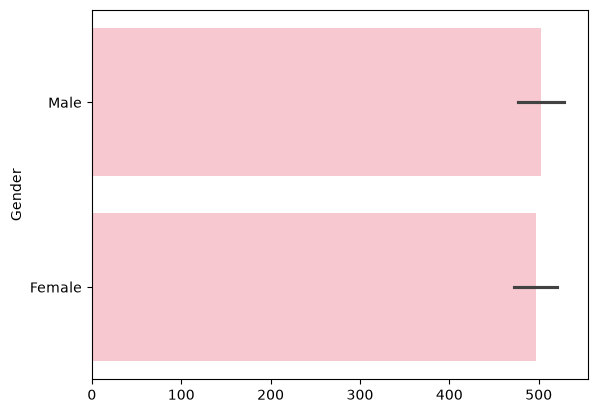

In [151]:
sns.barplot(df['Gender'],color='pink')

Figure 17: Age Distribution Histogram

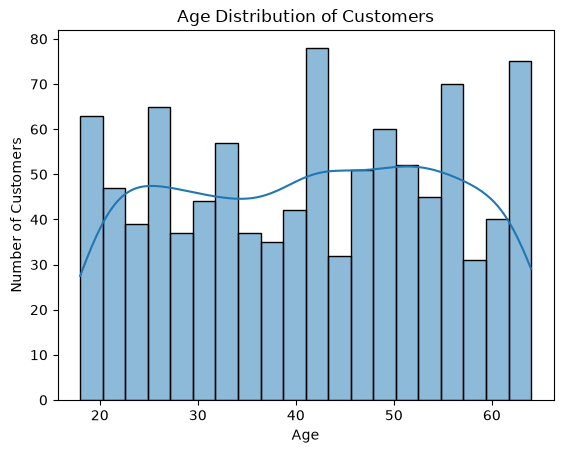

In [ ]:

sns.histplot(x='Age',data=df,bins=20,kde=True)
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.title('Age Distribution of Customers')
plt.show()

Figure 18: Revenue Distribution Histogram

<Axes: xlabel='Total Amount', ylabel='Count'>

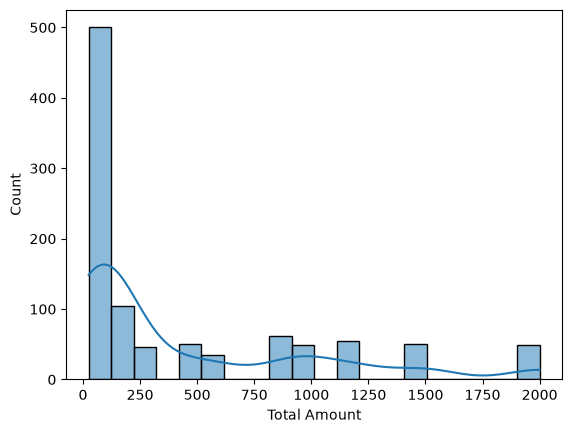

In [ ]:

sns.histplot(x='Total Amount',data=df,bins=20,kde=True)


Figure 19: Transaction Amount Boxplot



<Axes: xlabel='Total Amount'>

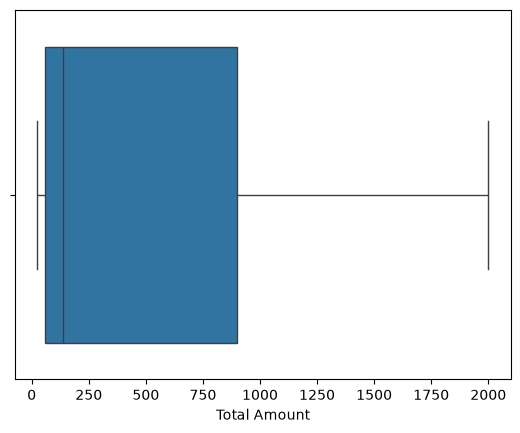

In [154]:
sns.boxplot(x=df['Total Amount'])

Figure 20: Correlation Heatmap

<Axes: >

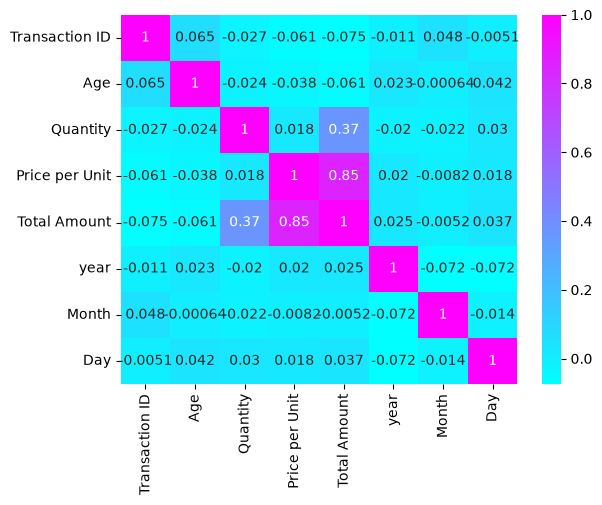

In [ ]:
corr=df.select_dtypes(include='number').corr()
sns.heatmap(corr,annot=True,cmap='cool')